## 1. Configuração e carregamento dos dados

In [1]:
import random, os
import numpy as np

SEED = 76

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# do ml
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (f1_score, r2_score, root_mean_squared_error, mean_absolute_error,
                             accuracy_score, confusion_matrix, recall_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

# visualizacoes
from sklearn.metrics import ConfusionMatrixDisplay

In [3]:
df_label = pd.read_csv("dados/02_treino_sinais_vitais_com_label.csv", header=None, names=['id', 'pSist', 'pDiast', 'qPA', 'pulso', 'resp', 'gravidade', 'rotulo_saida'])

In [4]:
df_label.head()

,id,pSist,pDiast,qPA,pulso,resp,gravidade,rotulo_saida
0,1,13.592433,12.220855,8.416754,75.921057,21.635259,40.000000,2
1,2,15.775386,13.586879,8.725890,63.813564,19.718734,41.530427,2
2,3,3.649369,1.904802,0.000000,197.210213,19.045471,52.730745,3
3,4,17.264362,13.700638,8.733333,143.636181,17.621141,34.679911,2
4,5,12.705183,9.485389,1.747626,82.636672,12.209535,69.375882,3


In [5]:
# colunas nao usadas
df_label = df_label.drop(columns=['pDiast', 'pSist'])

In [6]:
df_label.shape

(1500, 6)

## 2. Redes Neurais MLP

In [7]:
X = df_label[['qPA', 'pulso', 'resp']]
y = df_label["gravidade"]          
classi_y = df_label["rotulo_saida"]  # classes 

X_treino, X_teste, y_treino, y_teste, classi_y_treino, classi_y_teste = train_test_split(
    X, y, classi_y, test_size=0.2, random_state=SEED, stratify=classi_y
)

print(classi_y_teste.value_counts().sort_index())

rotulo_saida
1     47
2    166
3     81
4      6
Name: count, dtype: int64


normalização dos dados

In [24]:
model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(16, 32), max_iter=2000, random_state=SEED)
    ),
    transformer=StandardScaler()   
)

model.fit(X_treino, y_treino)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=76))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",StandardScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['qPA','pulso','resp']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,3
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=76))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,StandardScaler,StandardScaler()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"


In [25]:
y_pred = model.predict(X_teste)

r2 = r2_score(y_teste, y_pred)
rmse = root_mean_squared_error(y_teste, y_pred)
mae = mean_absolute_error(y_teste, y_pred)

print(f"R² Score: {r2:.4f}")
print(f"RMSE Score: {rmse:.4f}")
print(f"MAE Score: {mae:.4f}")
print("Iterações até convergir:", model.regressor_[-1].n_iter_)   

R² Score: 0.9538
RMSE Score: 3.5714
MAE Score: 2.5781
Iterações até convergir: 232


Classificação das classes de gravidade

In [36]:
classficador = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 32), max_iter=2000, random_state=SEED)
)
classficador.fit(X_treino, classi_y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[1,2,3,4]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['qPA','pulso','resp']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [37]:
resul = classficador.predict(X_teste)

In [38]:
f1_macro = f1_score(classi_y_teste, resul, average='macro')
print(f"F1 macro: {f1_macro:.4f}\n")

acc = accuracy_score(classi_y_teste, resul)
print(f"Acurácia: {acc:.4f}\n")

rec_macro = recall_score(classi_y_teste, resul, average="macro")
print(f"Recall (macro): {rec_macro:.4f}\n")

F1 macro: 0.8902

Acurácia: 0.9233

Recall (macro): 0.8738



In [39]:
resul_via_g = np.digitize(y_pred, bins=[25, 50, 75]) + 1

print("F1 macro (classificação direta):", round(f1_score(classi_y_teste, resul, average='macro'), 4))
print("F1 macro (via gravidade):", round(f1_score(classi_y_teste, resul_via_g, average='macro'), 4))
print(confusion_matrix(classi_y_teste, resul_via_g, labels=[1, 2, 3, 4]))

F1 macro (classificação direta): 0.8902
F1 macro (via gravidade): 0.7959
[[ 38   9   0   0]
 [  5 156   5   0]
 [  0   4  74   3]
 [  0   0   3   3]]


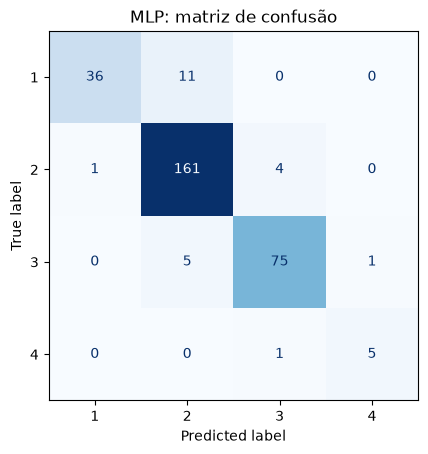

In [40]:
ConfusionMatrixDisplay.from_predictions(
    classi_y_teste, resul, labels=[1, 2, 3, 4],
    cmap='Blues', colorbar=False
)
plt.title('MLP: matriz de confusão')
plt.show()